# Diagnostic différentiel des maladies rares par ontologies

**Projet E1** — similarité sémantique sur la Human Phenotype Ontology (HPO) et les annotations Orphanet.

Une maladie rare se reconnaît à une *combinaison* de signes, rarement tous présents. Ce notebook montre, pas à pas :

1. les données : l'ontologie HPO et les annotations maladies → phénotypes ;
2. l'**information content** (IC) et la **mesure de Resnik** ;
3. le classement des maladies pour un patient, avec **explication** ;
4. l'**évaluation** sur des patients simulés, comparée à des baselines par mots-clés ;
5. les extensions : **signes absents**, **question suivante la plus discriminante**, **raisonnement OWL** (HermiT).

Prérequis : `python scripts/download_data.py` puis `python -m rarediag.evaluate` (pour les résultats d'évaluation).

In [1]:
import sys, math, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rarediag import load_index
from rarediag.baseline import Baselines
from rarediag.explain import explain_text, explain
from rarediag.evaluate import tie_aware_rank, summarize

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 110
index = load_index(ROOT / "data")
onto = index.onto
print(f"HPO {onto.version} : {len(onto)} termes sous « Phenotypic abnormality »")
print(f"Annotations {index.annotations_version} : {len(index.disease_ids)} maladies Orphanet")

HPO hp/releases/2026-09-01 : 19178 termes sous « Phenotypic abnormality »
Annotations 2026-09-02 : 4355 maladies Orphanet


## 1. Les données

**L'ontologie** est un graphe orienté acyclique : chaque terme a un ou plusieurs parents plus généraux (relation *is_a*). On ne garde que le sous-arbre `HP:0000118 Phenotypic abnormality`.

**Les annotations** (`phenotype.hpoa`) associent à chaque maladie Orphanet une liste de phénotypes, avec une fréquence (obligatoire, très fréquent, fréquent, occasionnel…).

Phénotypes par maladie : médiane 22, min 1, max 185
Termes à plusieurs parents (multi-héritage) : 3843 (20%)
Profondeur max de la hiérarchie : 12
Termes effectivement utilisés dans les annotations : 8669


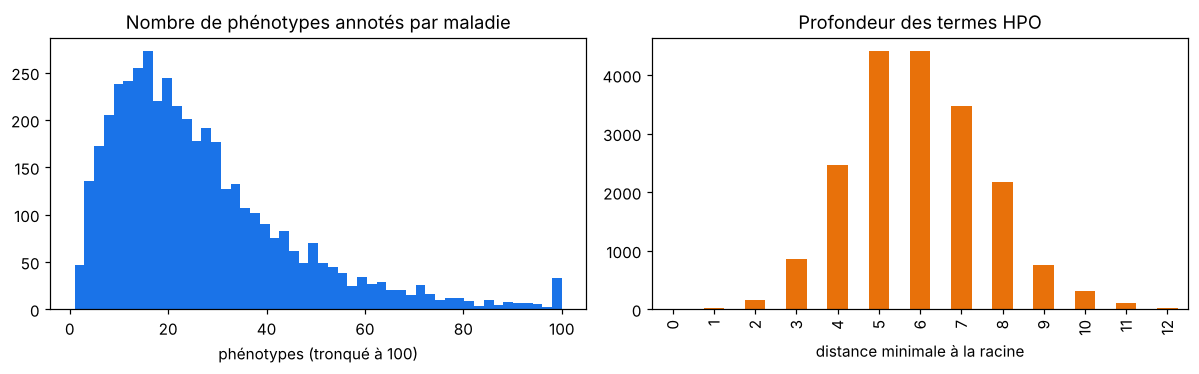

In [2]:
n_pheno = pd.Series({d: len(index.diseases[d].phenotypes) for d in index.disease_ids})
n_parents = pd.Series({t: len(onto.parents[t]) for t in onto.terms})
depth = pd.Series({t: onto.depth(t) for t in onto.terms})
print(f"Phénotypes par maladie : médiane {n_pheno.median():.0f}, min {n_pheno.min()}, max {n_pheno.max()}")
print(f"Termes à plusieurs parents (multi-héritage) : {(n_parents > 1).sum()} ({(n_parents > 1).mean():.0%})")
print(f"Profondeur max de la hiérarchie : {depth.max()}")
print(f"Termes effectivement utilisés dans les annotations : {len(index.annotated_terms)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(n_pheno.clip(upper=100), bins=50, color="#1a73e8")
ax[0].set_title("Nombre de phénotypes annotés par maladie"); ax[0].set_xlabel("phénotypes (tronqué à 100)")
depth.value_counts().sort_index().plot.bar(ax=ax[1], color="#e8710a")
ax[1].set_title("Profondeur des termes HPO"); ax[1].set_xlabel("distance minimale à la racine")
plt.tight_layout(); plt.show()

## 2. Information content et mesure de Resnik

Une maladie annotée par un terme l'est implicitement par tous ses ancêtres (*true path rule*). On note $p(t)$ la proportion de maladies annotées par $t$ après cette propagation :

$$IC(t) = -\log p(t)$$

Un terme rare (spécifique) est très informatif ; la racine, partagée par toutes les maladies, a un IC nul. La similarité de **Resnik** entre deux termes est l'IC de leur ancêtre commun le plus informatif (MICA) :

$$\text{sim}(t_1, t_2) = \max_{a \in \text{Anc}(t_1) \cap \text{Anc}(t_2)} IC(a)$$

Exemple : le chemin de *Ectopia lentis* (cristallin déplacé) jusqu'à la racine.

In [3]:
t = "HP:0001083"
chain = sorted(onto.ancestors(t), key=lambda a: -index.ic[a])
pd.DataFrame([{"terme": a, "libellé": onto.name(a), "maladies annotées": index.counts.get(a, 0),
               "IC": round(index.ic[a], 3)} for a in chain])

,terme,libellé,maladies annotées,IC
0,HP:0001083,Ectopia lentis,26,5.121
1,HP:0000517,Abnormal lens morphology,399,2.390
2,HP:0004328,Abnormal anterior eye segment morphology,789,1.708
3,HP:0012372,Abnormal eye morphology,1751,0.911
4,HP:0000478,Abnormality of the eye,2302,0.638
5,HP:0000118,Phenotypic abnormality,4355,-0.000


In [4]:
pairs = [("HP:0001083", "HP:0000545"),   # Ectopia lentis / Myopia
         ("HP:0001083", "HP:0000518"),   # Ectopia lentis / Cataract
         ("HP:0001166", "HP:0001238"),   # Arachnodactyly / Slender finger
         ("HP:0001083", "HP:0001166")]   # Ectopia lentis / Arachnodactyly
pd.DataFrame([{"terme 1": onto.name(a), "terme 2": onto.name(b), "MICA": onto.name(index.mica(a, b)),
               "Resnik": round(index.resnik(a, b), 3)} for a, b in pairs])

,terme 1,terme 2,MICA,Resnik
0,Ectopia lentis,Myopia,Abnormality of the eye,0.638
1,Ectopia lentis,Cataract,Abnormal lens morphology,2.390
2,Arachnodactyly,Slender finger,Slender finger,3.794
3,Ectopia lentis,Arachnodactyly,Phenotypic abnormality,-0.000


Deux signes oculaires partagent un ancêtre assez informatif ; un signe oculaire et un signe squelettique ne partagent que des ancêtres très généraux, donc une similarité faible.

L'IC croît bien quand on descend dans la hiérarchie (contrôlé par les tests sur toute l'ontologie) :

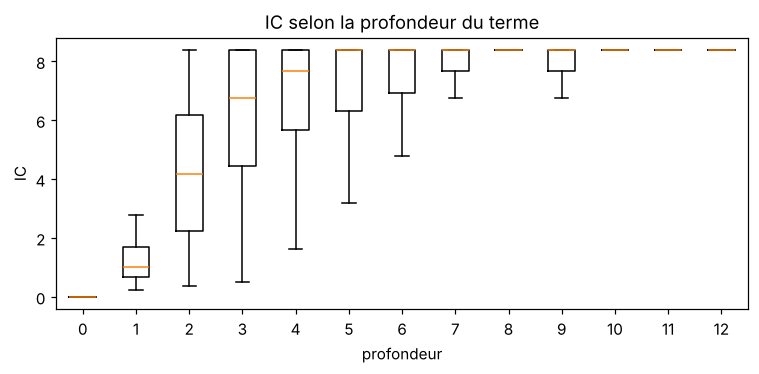

IC(enfant) >= IC(parent) pour toutes les arêtes : True


In [5]:
ic = pd.Series(index.ic)
fig, ax = plt.subplots(figsize=(7, 3.5))
data = [ic[depth[depth == d].index].values for d in range(0, 13)]
ax.boxplot(data, tick_labels=range(0, 13), showfliers=False)
ax.set_xlabel("profondeur"); ax.set_ylabel("IC"); ax.set_title("IC selon la profondeur du terme")
plt.tight_layout(); plt.show()
print("IC(enfant) >= IC(parent) pour toutes les arêtes :",
      all(index.ic[c] >= index.ic[p] - 1e-12 for c in onto.terms for p in onto.parents[c]))

## 3. Classer les maladies pour un patient

Le score d'une maladie $D$ pour un profil patient $Q$ est le *best-match average* de Köhler et al. (2009) : pour chaque signe du patient, on prend le meilleur appariement dans la maladie, puis on fait la moyenne. La version symétrique fait aussi la moyenne dans l'autre sens (chaque phénotype de la maladie cherche son meilleur appariement chez le patient), ce qui pénalise les maladies très richement annotées qui « expliquent tout ».

**Optimisation** : $\max_{t \in D} \text{sim}(q, t)$ est l'IC maximal parmi les ancêtres de $q$ présents dans la fermeture de $D$. Avec un index inversé, classer les 4 355 maladies prend environ une milliseconde.

In [6]:
marfan = ["HP:0001166", "HP:0001083", "HP:0002616", "HP:0000098"]
print("Patient :", ", ".join(onto.name(q) for q in marfan), "\n")
for k, (d, s) in enumerate(index.rank(marfan, "resnik_sym", top=8), 1):
    print(f"{k}. {s:.3f}  {d:13s} {index.diseases[d].name}")
print()
print(explain_text(index, marfan, "ORPHA:558", "resnik_sym"))

Patient : Arachnodactyly, Ectopia lentis, Aortic root aneurysm, Tall stature 

1. 2.854  ORPHA:558     Marfan syndrome
2. 2.768  ORPHA:115     Congenital contractural arachnodactyly
3. 2.664  ORPHA:91387   Familial thoracic aortic aneurysm and aortic dissection
4. 2.388  ORPHA:284979  Neonatal Marfan syndrome
5. 2.200  ORPHA:394     Homocystinuria due to cystathionine beta-synthase deficiency
6. 2.181  ORPHA:284984  Aneurysm-osteoarthritis syndrome
7. 2.135  ORPHA:230851  Cardiac-valvular Ehlers-Danlos syndrome
8. 2.106  ORPHA:60030   Loeys-Dietz syndrome

ORPHA:558 — Marfan syndrome   (score 2.854)
  • Aortic root aneurysm ↔ Aortic root aneurysm [identique] IC=5.24, fréquence 90%
  • Ectopia lentis ↔ Ectopia lentis [identique] IC=5.12, fréquence 55%
  • Arachnodactyly ↔ Arachnodactyly [identique] IC=3.94, fréquence 90%
  • Tall stature ↔ Slender build [la maladie précise ce signe via « Tall stature »] IC=3.76, fréquence 90%


**Lecture de l'explication** : chaque signe du patient est relié au phénotype de la maladie qui le « couvre » le mieux, via un ancêtre commun dont l'IC mesure la force de l'argument. Un appariement *identique* à fort IC (anévrisme de la racine aortique) pèse beaucoup plus qu'un appariement lointain.

### Pourquoi la hiérarchie compte : un patient décrit de façon imprécise

Un clinicien ne note pas toujours le terme le plus précis. Remplaçons les signes par leur parent :

In [7]:
vague = [sorted(onto.parents[q])[0] for q in marfan]
print("Patient imprécis :", ", ".join(onto.name(q) for q in vague))
b = Baselines(index)
methods = {"Mots-clés": b.keywords, "Termes exacts": b.exact, "Jaccard hiérarchique": b.graph_jaccard,
           "Resnik Q→D": lambda q: index.scores(q, "resnik"), "Resnik symétrique": lambda q: index.scores(q, "resnik_sym")}
i = index.index_of["ORPHA:558"]
pd.DataFrame([{"méthode": m, "rang du Marfan (précis)": tie_aware_rank(f(marfan), i),
               "rang du Marfan (imprécis)": tie_aware_rank(f(vague), i)} for m, f in methods.items()])

Patient imprécis : Slender finger, Abnormal lens morphology, Thoracic aortic aneurysm, Abnormality of body height


,méthode,rang du Marfan (précis),rang du Marfan (imprécis)
0,Mots-clés,29.0,180.0
1,Termes exacts,35.5,2188.5
2,Jaccard hiérarchique,245.0,516.5
3,Resnik Q→D,1.0,1.0
4,Resnik symétrique,1.0,2.0


Avec des termes imprécis, le recouvrement exact ne trouve plus rien de commun (rang « ex æquo » au milieu de milliers de maladies), alors que Resnik remonte la hiérarchie et garde le Marfan bien classé.

## 4. Évaluation sur patients simulés

Protocole inspiré de Köhler et al. (2009) : pour 500 maladies tirées au hasard par scénario, on tire 5 phénotypes (pondérés par leur fréquence), puis on dégrade le profil :

* **imprécision** : chaque signe est remplacé avec une probabilité donnée par un de ses parents ;
* **bruit** : on ajoute des signes aléatoires sans rapport avec la maladie.

On mesure le **rang** de la bonne maladie (les ex æquo sont départagés en moyenne), le **top-1**, le **top-10** et le **MRR** (moyenne de 1/rang). Les résultats sont produits par `python -m rarediag.evaluate --n 500 --seed 42` et contrôlés par `verifier/verify.py`.

In [8]:
R = ROOT / "results"
ranks = pd.read_csv(R / "ranks.csv")
summary = summarize(ranks)
summary

top1  top10  rang_median    MRR
scenario                              method                                                   
parfait                               Mots-clés (baseline)     0.554  0.840         1.00  0.650
                                      Termes exacts (Jaccard)  0.658  0.910         1.00  0.747
                                      Jaccard hiérarchique     0.388  0.634         3.00  0.475
                                      Resnik Q→D               0.838  0.990         1.00  0.923
                                      Resnik symétrique        0.890  0.996         1.00  0.932
imprécision 50 %                      Mots-clés (baseline)     0.338  0.600         5.00  0.428
                                      Termes exacts (Jaccard)  0.308  0.596         5.00  0.405
                                      Jaccard hiérarchique     0.300  0.542         8.00  0.378
                                      Resnik Q→D               0.704  0.968         1.00  0.826
                                      Resnik symétrique        0.784  0.986         1.00  0.862
imprécision 100 %                     Mots-clés (baseline)     0.068  0.274        42.25  0.131
                                      Termes exacts (Jaccard)  0.004  0.032      2219.75  0.014
                                      Jaccard hiérarchique     0.202  0.402        23.00  0.271
                                      Resnik Q→D               0.386  0.880         1.50  0.593
                                      Resnik symétrique        0.602  0.928         1.00  0.714
bruit +2                              Mots-clés (baseline)     0.598  0.844         1.00  0.688
                                      Termes exacts (Jaccard)  0.712  0.928         1.00  0.789
                                      Jaccard hiérarchique     0.404  0.666         3.00  0.492
                                      Resnik Q→D               0.650  0.924         1.00  0.756
                                      Resnik symétrique        0.736  0.968         1.00  0.823
imprécision 50 % + bruit +2           Mots-clés (baseline)     0.344  0.600         4.00  0.434
                                      Termes exacts (Jaccard)  0.316  0.598         5.00  0.414
                                      Jaccard hiérarchique     0.334  0.526         7.00  0.404
                                      Resnik Q→D               0.402  0.800         2.00  0.542
                                      Resnik symétrique        0.534  0.874         1.00  0.647
3 signes, imprécision 50 % + bruit +1 Mots-clés (baseline)     0.178  0.424        21.25  0.269
                                      Termes exacts (Jaccard)  0.154  0.410        18.00  0.252
                                      Jaccard hiérarchique     0.130  0.332        34.00  0.198
                                      Resnik Q→D               0.252  0.622         5.50  0.380
                                      Resnik symétrique        0.352  0.696         3.00  0.473

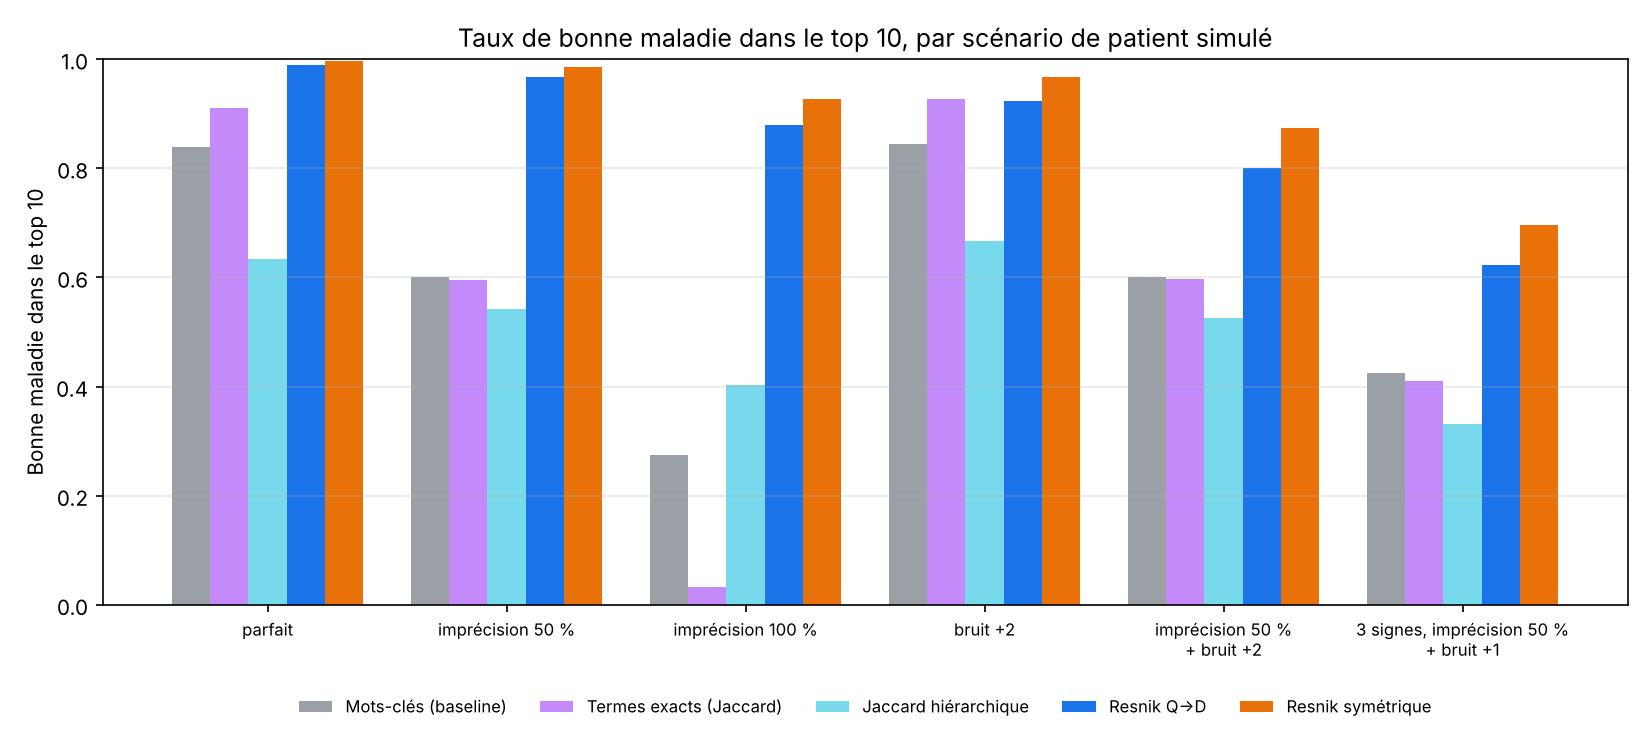

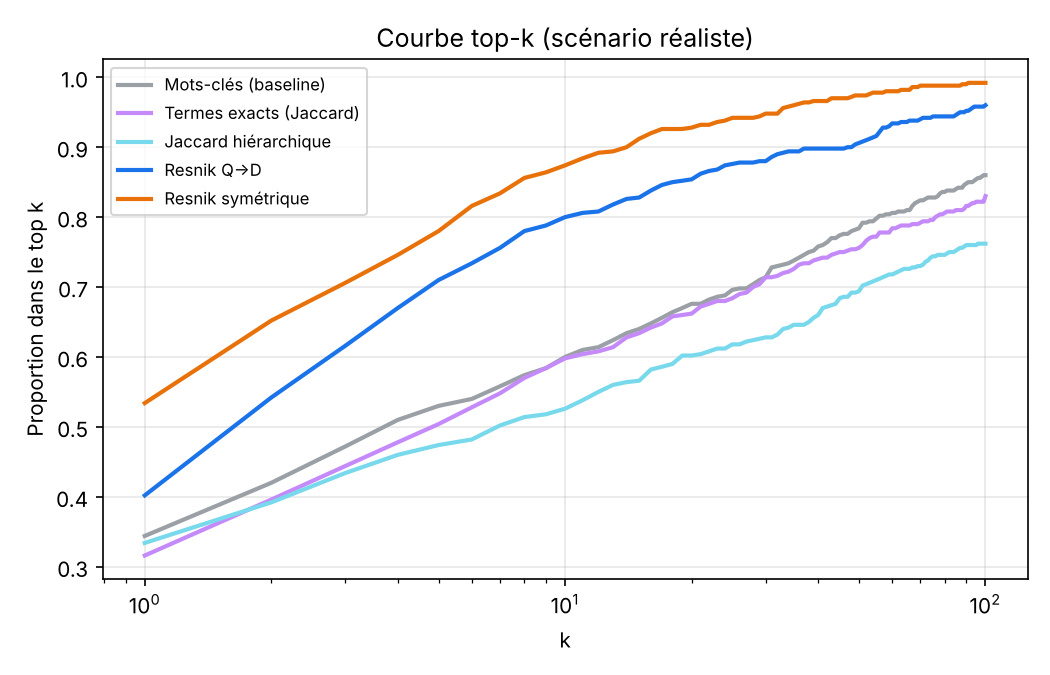

In [9]:
from IPython.display import Image, display
display(Image(R / "figures" / "top10_par_scenario.png"))
display(Image(R / "figures" / "courbe_topk.png", width=600))

### Analyse

* **Profils parfaits** : toutes les méthodes fonctionnent, mais Resnik place la bonne maladie dans le top 10 dans 99 % des cas contre 84 % pour les mots-clés.
* **Imprécision** : c'est là que l'ontologie fait la différence. Avec 100 % de signes généralisés, le recouvrement exact s'effondre (3 % dans le top 10) ; Resnik symétrique reste à 93 %.
* **Jaccard hiérarchique** : utiliser la hiérarchie *sans* l'IC est même pire que les mots-clés. Ce qui compte n'est pas seulement de partager des ancêtres, mais de partager des ancêtres **informatifs**.
* **Bruit seul** : le Jaccard exact fait un meilleur top-1 que Resnik Q→D. C'est un résultat honnête à expliquer, ci-dessous.
* **Version symétrique** : elle est la meilleure dans tous les scénarios.

### Analyse d'erreur : pourquoi Resnik Q→D souffre du bruit

Un signe de bruit cherche son meilleur appariement dans chaque maladie. Une maladie annotée par 100 phénotypes en trouve presque toujours un proche ; une maladie à 5 phénotypes, non. Le score Q→D favorise donc les maladies **richement annotées**, quelles que soient les vraies. Vérifions-le sur le scénario « bruit +2 » :

In [10]:
from rarediag.simulate import PatientSimulator, Scenario
sim = PatientSimulator(index, seed=7)
pats = sim.cohort(Scenario("bruit", n_terms=5, noise=2), 200)
rows = []
for p in pats:
    for m in ["resnik", "resnik_sym"]:
        top1 = index.rank(p.terms, m, top=1)[0][0]
        rows.append({"méthode": m, "phénotypes du 1er candidat": len(index.diseases[top1].phenotypes),
                     "phénotypes de la bonne maladie": len(index.diseases[p.disease_id].phenotypes)})
pd.DataFrame(rows).groupby("méthode").median()

,phénotypes du 1er candidat,phénotypes de la bonne maladie
méthode,,
resnik,36.0,22.0
resnik_sym,17.0,22.0


Le premier candidat de Resnik Q→D a nettement plus d'annotations que la vraie maladie : c'est le biais attendu. La direction maladie → patient du score symétrique le corrige, car une maladie à 100 phénotypes dont seuls 5 sont retrouvés chez le patient est alors pénalisée.

## 5. Extensions

### 5.1 Signes absents

Un clinicien sait aussi ce que le patient **n'a pas**. Pour chaque signe absent $x$, une maladie qui possède $x$ (ou un de ses sous-types) avec la fréquence $f$ est pénalisée de $\lambda \cdot f \cdot IC(x)$. Pour simuler des signes absents réalistes, on tire des signes des diagnostics concurrents (ceux qu'un médecin vérifierait), absents de la vraie maladie.

,scenario,method,top1,top10,rang_median,MRR
0,signes absents,Resnik (signes présents seuls),0.207,0.603,6.0,0.333
1,signes absents,Resnik + absents (λ=0.5),0.247,0.660,4.0,0.386
2,signes absents,Resnik + absents (λ=1.0),0.250,0.670,4.0,0.399
3,signes absents,Resnik + absents (λ=2.0),0.263,0.673,4.0,0.411


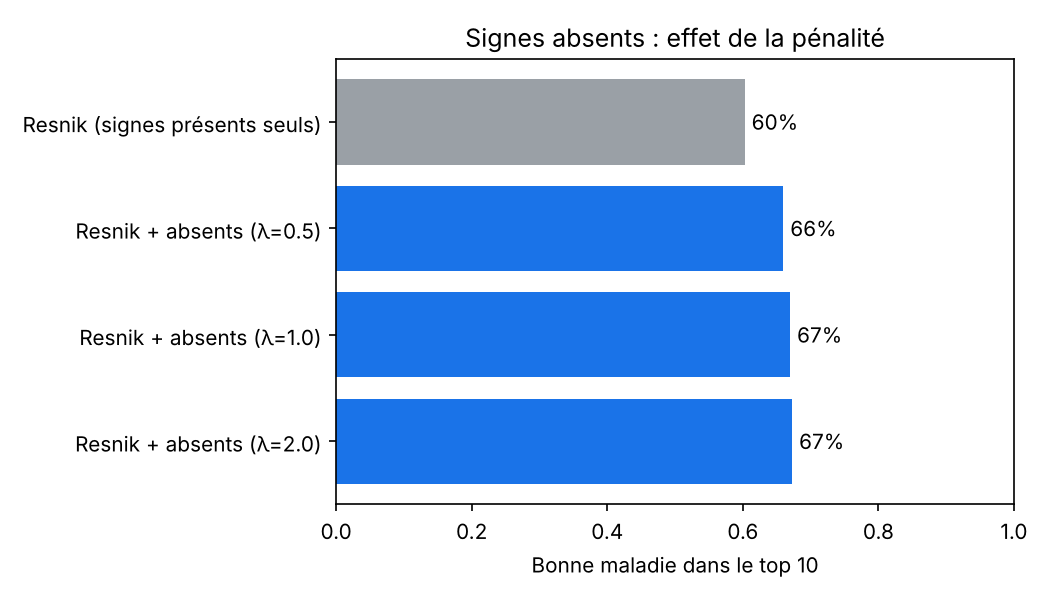

In [11]:
display(pd.read_csv(R / "summary_absent.csv"))
display(Image(R / "figures" / "signes_absents.png", width=550))

### 5.2 Question suivante la plus discriminante

Les scores des 20 premiers candidats sont transformés en probabilités ($p(d) \propto e^{\text{score}/T}$). Pour chaque signe candidat $x$, on estime $P(x \mid d)$ par sa fréquence dans la maladie et on calcule le **gain d'information** attendu (réduction d'entropie). On propose le signe de gain maximal.

Évaluation : consultation simulée à partir de 2 signes ; à chaque tour, la réponse (présent / absent) est tirée selon la fréquence du signe dans la vraie maladie.

,method,questions,top1,top10,MRR
0,aucune question,0,0.090,0.525,0.247
1,aucune question,1,0.090,0.525,0.247
2,aucune question,2,0.090,0.525,0.247
3,aucune question,3,0.090,0.525,0.247
4,question au hasard,0,0.090,0.525,0.247
5,question au hasard,1,0.105,0.550,0.262
6,question au hasard,2,0.120,0.575,0.281
7,question au hasard,3,0.125,0.590,0.296
8,gain d'information max,0,0.090,0.525,0.247
9,gain d'information max,1,0.170,0.625,0.331


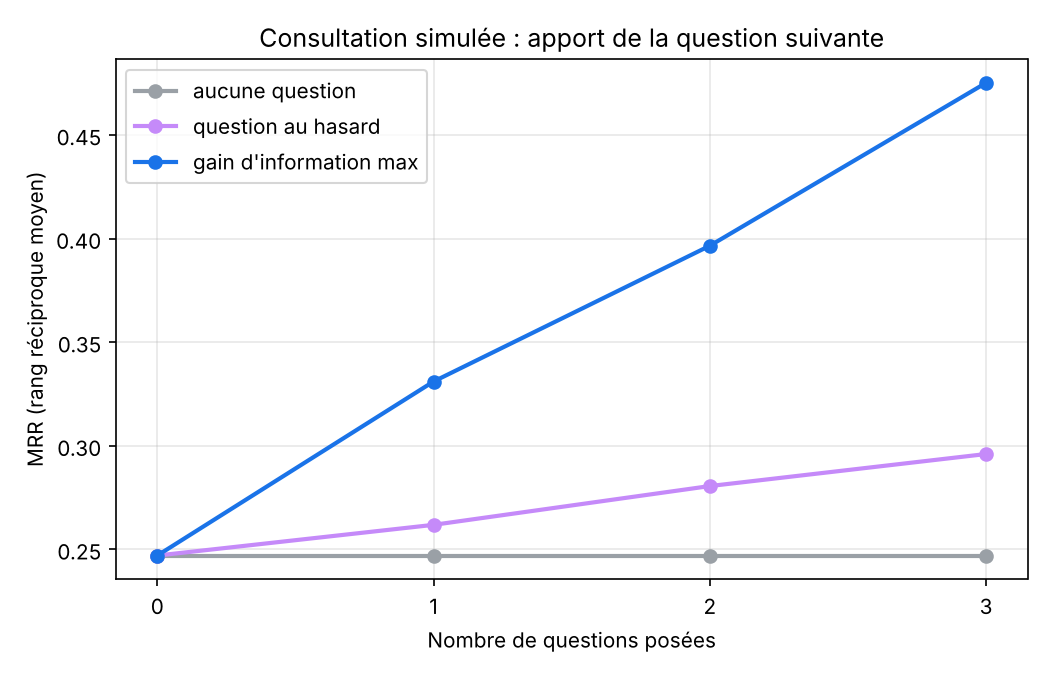

In [12]:
display(pd.read_csv(R / "summary_questions.csv"))
display(Image(R / "figures" / "questions_mrr.png", width=550))

In [13]:
from rarediag.next_question import best_questions
q = ["HP:0001166", "HP:0001083"]    # arachnodactylie + ectopie du cristallin
print("Candidats :", ", ".join(index.diseases[d].name for d, _ in index.rank(q, top=5)))
for x in best_questions(index, q):
    print(f"  ? {x.name:40s} gain {x.gain:.2f} bit   P(présent) = {x.p_yes:.2f}")

Candidats : Congenital contractural arachnodactyly, Blindness-scoliosis-arachnodactyly syndrome, Neonatal Marfan syndrome, Homocystinuria due to cystathionine beta-synthase deficiency, Marfan syndrome
  ? Flexion contracture                      gain 0.67 bit   P(présent) = 0.30
  ? Decreased body weight                    gain 0.63 bit   P(présent) = 0.47
  ? Slender build                            gain 0.61 bit   P(présent) = 0.32
  ? Aortic aneurysm                          gain 0.61 bit   P(présent) = 0.32
  ? Mitral regurgitation                     gain 0.61 bit   P(présent) = 0.26


Trois questions bien choisies font passer le top-1 de 9 % à 30,5 %, contre 12,5 % pour des questions au hasard parmi les signes des candidats.

### 5.3 Raisonnement OWL avec HermiT

On traduit un sous-domaine (les 1 097 maladies touchant le tissu conjonctif, `HP:0003549`) en ontologie OWL :

* chaque terme HPO devient une classe, avec ses axiomes `SubClassOf` ;
* chaque maladie devient une classe : `Maladie ⊑ ∃hasPhenotype.T` pour chaque phénotype, `Maladie ⊑ ¬∃hasPhenotype.T` pour chaque annotation NOT ;
* le patient devient une classe définie : `Compatible ≡ Disease ⊓ ∃hasPhenotype.Q1 ⊓ … ⊓ ∃hasPhenotype.Qn`.

Le raisonneur classe sous `Compatible` les maladies qui ont chaque signe ou un de ses sous-types, en exploitant la hiérarchie. On compare avec le calcul direct par fermetures.

In [14]:
from rarediag.owl_reasoning import subdomain, build_and_reason, contradictory_annotations
ds = subdomain(index, "HP:0003549")
res = build_and_reason(index, ds, ["HP:0001166", "HP:0001083"])
print(f"{len(ds)} maladies, {res.n_classes} classes, {res.n_axioms} axiomes ; HermiT : {res.reasoning_time_s:.1f} s")
print("Compatibles (raisonneur) :", [index.diseases[d].name for d in res.compatible])
print("Identique au calcul par fermetures :", res.compatible == res.expected_compatible)
print("Classes insatisfiables :", res.unsatisfiable)

1097 maladies, 7872 classes, 51853 axiomes ; HermiT : 8.7 s
Compatibles (raisonneur) : ['Congenital contractural arachnodactyly', 'Neonatal Marfan syndrome', 'Homocystinuria due to cystathionine beta-synthase deficiency', 'Marfan syndrome', 'Stickler syndrome']
Identique au calcul par fermetures : True
Classes insatisfiables : ['ORPHA:217059']


In [15]:
# Le même filtre logique échoue dès qu'un signe est bruité, là où Resnik reste robuste
noisy = ["HP:0001166", "HP:0001083", "HP:0000365"]   # + surdité, absente du Marfan
res2 = build_and_reason(index, ds, noisy)
print("Compatibles avec un signe bruité :", [index.diseases[d].name for d in res2.compatible])
r = dict((d, k) for k, (d, _) in enumerate(index.rank(noisy, "resnik_sym"), 1))
print("Rang du Marfan avec Resnik symétrique :", r["ORPHA:558"])

Compatibles avec un signe bruité : ['Stickler syndrome']
Rang du Marfan avec Resnik symétrique : 7


Le raisonnement logique est **exact mais tout-ou-rien** : un seul signe sans rapport suffit à éliminer la bonne maladie. La similarité sémantique est **graduée** et tolère le bruit. Les deux sont complémentaires : la logique pour les contraintes sûres (exclusions explicites, cohérence), la similarité pour classer.

**Contrôle de cohérence des annotations** : une maladie annotée par un signe et par « NOT » d'un de ses ancêtres est une classe **insatisfiable** pour le raisonneur. Sur toute la base :

In [16]:
pd.DataFrame([{"maladie": index.diseases[d].name, "annoté NOT": onto.name(x), "mais annoté présent": onto.name(t)}
              for d, x, t in contradictory_annotations(index)])

,maladie,annoté NOT,mais annoté présent
0,Isolated nail clubbing,Abnormality of the skin,Unusual fungal nail infection
1,Childhood-onset spasticity with hyperglycinemia,Cognitive impairment,Short attention span


Ce sont de vraies incohérences dans la version 2026-09 des annotations, détectées automatiquement (un ongle fongique est un signe cutané ; un déficit d'attention est une atteinte cognitive).

## 6. Conclusion et limites

* La similarité de Resnik sur HPO **surpasse nettement** le recouvrement de mots-clés dès que les signes sont imprécis : 87 % contre 60 % dans le top 10 sur le scénario réaliste.
* La version **symétrique** corrige le biais vers les maladies richement annotées.
* Les extensions apportent un gain mesuré : signes absents (+7 points de top 10), questions par gain d'information (top-1 ×3,4 en 3 questions).

**Limites** : les patients sont simulés à partir des annotations elles-mêmes, ce qui est optimiste par rapport à de vrais patients. L'IC dépend du corpus (ici Orphanet seul). Les fréquences ne sont utilisées que pour les extensions, pas dans le score principal. Ce projet est un démonstrateur pédagogique et non un dispositif médical.

**Référence** : Köhler S. et al., *Clinical diagnostics in human genetics with semantic similarity searches in ontologies*, AJHG 85(4), 2009.